#STAT 4630 Lab 3: Classification and Model Evaluation


Member 1: Delina Ogbe

Member 2: Sesen Gojela

Member 3: Aditi Shanbhag

###Implementations

In [2]:
needed <- c("ISLR2", "MASS", "class", "pROC", "yardstick")
missing <- needed[!vapply(needed, requireNamespace, logical(1), quietly = TRUE)]
if (length(missing) > 0) {
  install.packages(missing, repos = "https://cloud.r-project.org")
}
stopifnot(all(vapply(needed, requireNamespace, logical(1), quietly = TRUE)))

knitr::opts_chunk$set(fig.width = 7, fig.height = 4.5, digits = 3)
options(width = 88)
RNGkind("Mersenne-Twister", "Inversion", "Rejection")

Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘sparsevctrs’, ‘hardhat’




In [3]:
library(ISLR2)
library(pROC)
library(yardstick)

# Pre-define the metric columns and names as specified in the resources
metric_names <- c("threshold", "tp", "fn", "fp", "tn", "accuracy",
                  "recall", "specificity", "fpr", "precision")
reported_names <- c("threshold", "TP", "FN", "FP", "TN", "accuracy",
                    "recall", "specificity", "FPR", "precision")

Type 'citation("pROC")' for a citation.


Attaching package: ‘pROC’


The following objects are masked from ‘package:stats’:

    cov, smooth, var




### Section 1 - Weekly: Split & Explore the Data

In [4]:
weekly <- ISLR2::Weekly
weekly$Direction <- factor(weekly$Direction, levels = c("Down", "Up"))
w_train <- subset(weekly, Year <= 2006)
w_valid <- subset(weekly, Year >= 2007 & Year <= 2008)
w_test  <- subset(weekly, Year >= 2009)

data.frame(set = c("Training: 1990-2006", "Validation: 2007-2008",
                   "Test: 2009-2010"),
           n = c(nrow(w_train), nrow(w_valid), nrow(w_test)))

set,n
<chr>,<int>
Training: 1990-2006,880
Validation: 2007-2008,105
Test: 2009-2010,104


In [5]:
str(w_train)
colSums(is.na(w_train))
summary(w_train[, c("Lag1", "Lag2", "Volume")])
table(w_train$Direction)
prop.table(table(w_train$Direction))
cor(w_train[, c("Lag1", "Lag2", "Volume")])

'data.frame':	880 obs. of  9 variables:
 $ Year     : num  1990 1990 1990 1990 1990 1990 1990 1990 1990 1990 ...
 $ Lag1     : num  0.816 -0.27 -2.576 3.514 0.712 ...
 $ Lag2     : num  1.572 0.816 -0.27 -2.576 3.514 ...
 $ Lag3     : num  -3.936 1.572 0.816 -0.27 -2.576 ...
 $ Lag4     : num  -0.229 -3.936 1.572 0.816 -0.27 ...
 $ Lag5     : num  -3.484 -0.229 -3.936 1.572 0.816 ...
 $ Volume   : num  0.155 0.149 0.16 0.162 0.154 ...
 $ Today    : num  -0.27 -2.576 3.514 0.712 1.178 ...
 $ Direction: Factor w/ 2 levels "Down","Up": 1 1 2 2 2 1 2 2 2 1 ...


Year      Lag1      Lag2      Lag3      Lag4      Lag5    Volume     Today 
        0         0         0         0         0         0         0         0 
Direction 
        0

      Lag1               Lag2              Volume       
 Min.   :-11.0500   Min.   :-11.0500   Min.   :0.08747  
 1st Qu.: -1.0945   1st Qu.: -1.0893   1st Qu.:0.28776  
 Median :  0.2435   Median :  0.2530   Median :0.65369  
 Mean   :  0.1862   Mean   :  0.1893   Mean   :0.86281  
 3rd Qu.:  1.3197   3rd Qu.:  1.3255   3rd Qu.:1.33221  
 Max.   :  7.7800   Max.   :  7.7800   Max.   :2.98983  


Down   Up 
 388  492 


     Down        Up 
0.4409091 0.5590909 

,Lag1,Lag2,Volume
Lag1,1.00000000,-0.07920574,-0.03214347
Lag2,-0.07920574,1.00000000,-0.06534721
Volume,-0.03214347,-0.06534721,1.00000000


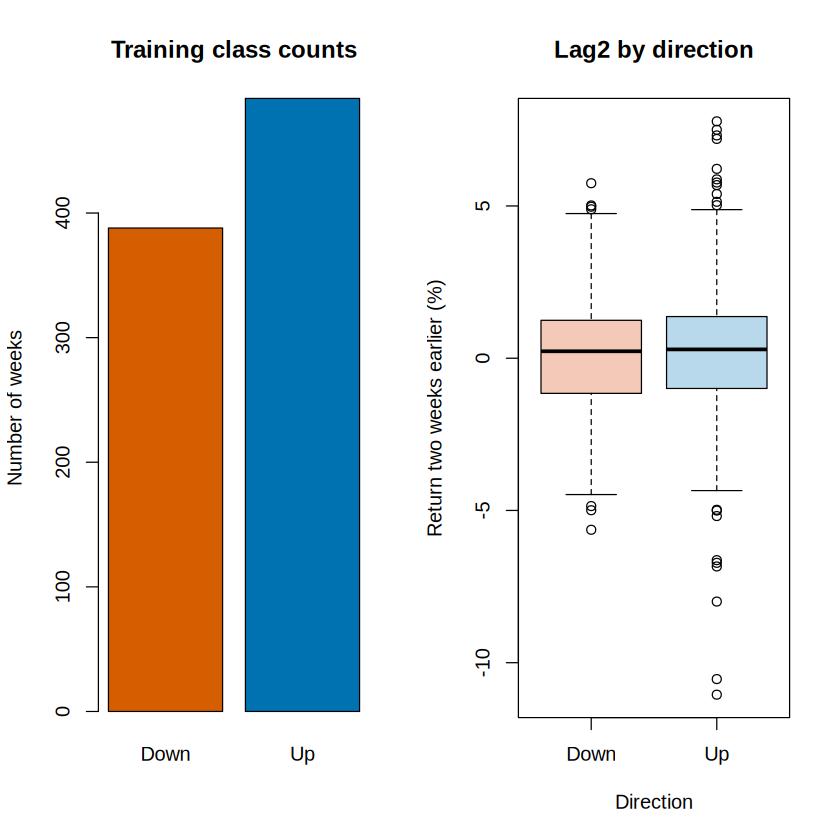

In [6]:
old_par <- par(mfrow = c(1, 2))
barplot(table(w_train$Direction), col = c("#D55E00", "#0072B2"),
        ylab = "Number of weeks", main = "Training class counts")
boxplot(Lag2 ~ Direction, data = w_train,
        col = c("#F4C9B8", "#B8D9EC"),
        ylab = "Return two weeks earlier (%)", main = "Lag2 by direction")

In [7]:
par(old_par)

**Q1.1**

Each row represents a single week's of S&P 500 stock market data between 1990 and 2010. We are trying to predict the "Direction" of a current week, whether it be "Down" or "Up". "Up" is the positive class, and "Lag1" and "Lag2" are the predictors. As "Today" reveals the current week's percentage return, using it to predict the "Direction" of the coming week would be an instance of data leakage, as we'd essentially be using the true outcome to help "predict" the outcome. Furthermore, since "Volume" is the average daily shares traded during the current week, this metric would only be available at the end of the week; thus, we wouldn't be able to use it at the beginning of the week when we're attempting to predict a week's "Direction".  



**Q1.2**

388 training weeks (44.091%) are "Down" and 492 training weeks (55.91%) are "Up". There appears to be no values missing as well, as "colSums(is.na(w_train)" (which sums the boolean values of each column) returns 0 for each column. Lastly, the two groups appear to heavily overlap (their means and medians, for instance, seem to be extremely similar to one another); thus, "Lag2" does not appear to separate them without any mistakes.




In [8]:
# Number of Training Weeks in Each Group
class_counts <- table(w_train$Direction)
print(class_counts)

# What Returns a "0"?
colSums(is.na(w_train))


Down   Up 
 388  492 


Year      Lag1      Lag2      Lag3      Lag4      Lag5    Volume     Today 
        0         0         0         0         0         0         0         0 
Direction 
        0

**Q1.3**

Upon plotting "Volume" against "Year", we see that as the years progress, the volume increases. Additionally, we train on earlier weeks and check the model on later weeks to prevent data leakage.

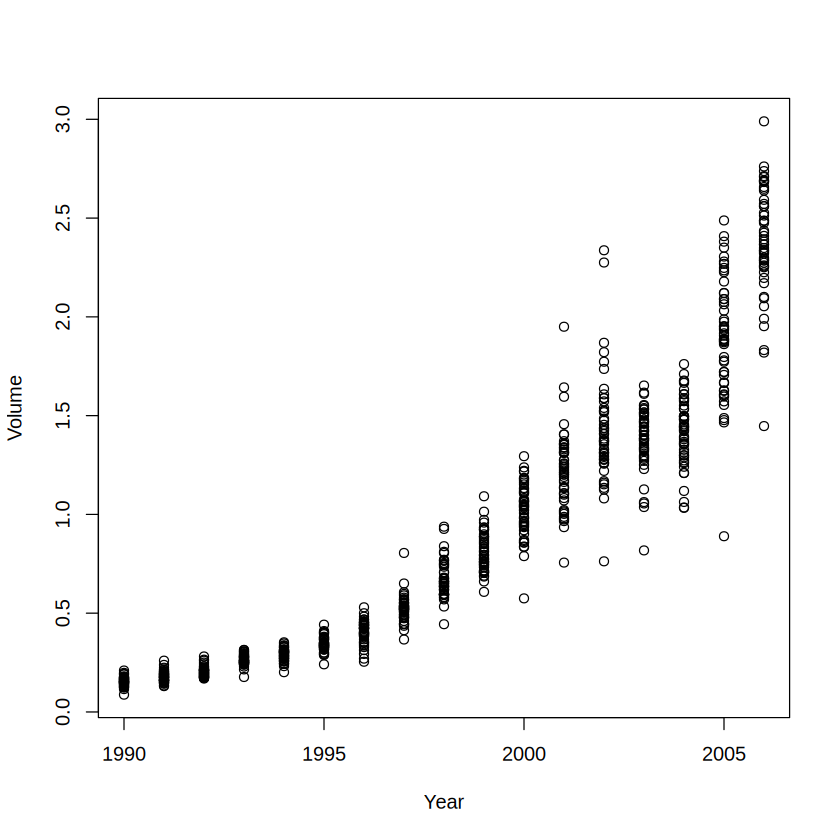

In [9]:
plot(Volume ~ Year, data = w_train,
     xlab = "Year", ylab = "Volume")

### Section 2 - Weekly: Logistic Regression, KNN, & LDA

In [10]:
w_glm <- glm(Direction ~ Lag1 + Lag2, data = w_train, family = binomial())
summary(w_glm)
w_glm_valid <- as.numeric(predict(w_glm, newdata = w_valid, type = "response"))
w_glm_class <- factor(ifelse(w_glm_valid >= .50, "Up", "Down"),
                      levels = levels(w_valid$Direction))
table(Actual = w_valid$Direction, Predicted = w_glm_class)


Call:
glm(formula = Direction ~ Lag1 + Lag2, family = binomial(), data = w_train)

Coefficients:
            Estimate Std. Error z value Pr(>|z|)    
(Intercept)  0.23797    0.06861   3.468 0.000524 ***
Lag1        -0.03545    0.03320  -1.068 0.285605    
Lag2         0.03560    0.03318   1.073 0.283392    
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

(Dispersion parameter for binomial family taken to be 1)

    Null deviance: 1207.6  on 879  degrees of freedom
Residual deviance: 1205.1  on 877  degrees of freedom
AIC: 1211.1

Number of Fisher Scoring iterations: 4


      Predicted
Actual Down Up
  Down    3 50
  Up      1 51

In [11]:
w_features <- c("Lag1", "Lag2")
w_x_train <- scale(as.matrix(w_train[, w_features]))
w_center <- attr(w_x_train, "scaled:center")
w_scale <- attr(w_x_train, "scaled:scale")
stopifnot(all(w_scale > 0))
w_x_valid <- scale(as.matrix(w_valid[, w_features]),
                   center = w_center, scale = w_scale)

k_grid <- c(1, 5, 11, 21)
w_knn_valid <- lapply(k_grid, function(k) {
  set.seed(4630 + k)
  predicted <- class::knn(w_x_train, w_x_valid, cl = w_train$Direction,
                          k = k, prob = TRUE)
  # The package returns the winning class's vote fraction; convert to P(Up).
  winning_fraction <- attr(predicted, "prob")
  ifelse(predicted == "Up", winning_fraction, 1 - winning_fraction)
})
knn_validation <- data.frame(
  K = k_grid,
  accuracy = vapply(w_knn_valid, function(p) {
    predicted <- factor(ifelse(p >= .50, "Up", "Down"),
                         levels = levels(w_valid$Direction))
    yardstick::accuracy_vec(w_valid$Direction, predicted)
  }, numeric(1))
)
knn_validation

# Predeclared rule: maximize validation accuracy; if tied, use larger K.
best_k <- max(knn_validation$K[
  knn_validation$accuracy == max(knn_validation$accuracy)])
w_knn_selected_valid <- w_knn_valid[[match(best_k, k_grid)]]
best_k

K,accuracy
<dbl>,<dbl>
1,0.5619048
5,0.5428571
11,0.5619048
21,0.4952381


[1] 11

In [12]:
w_lda <- MASS::lda(Direction ~ Lag1 + Lag2, data = w_train)
w_lda_valid <- predict(w_lda, newdata = w_valid)$posterior[, "Up"]

w_valid_scores <- list(Logistic = w_glm_valid,
                       KNN = w_knn_selected_valid, LDA = w_lda_valid)
# roc() creates score objects; coords() evaluates a specified threshold.
w_rocs <- lapply(w_valid_scores, function(p) {
  pROC::roc(w_valid$Direction, p, levels = c("Down", "Up"),
            direction = "<", quiet = TRUE)
})
w_validation <- do.call(rbind, lapply(names(w_valid_scores), function(method) {
  row <- pROC::coords(w_rocs[[method]], x = .50, input = "threshold",
                       ret = metric_names) |>
    setNames(reported_names)
  predicted <- factor(ifelse(w_valid_scores[[method]] >= .50, "Up", "Down"),
                       levels = levels(w_valid$Direction))
  row$F1 <- yardstick::f_meas_vec(w_valid$Direction, predicted,
                                 event_level = "second")
  cbind(method = method, row)
}))
rownames(w_validation) <- NULL
w_validation

method,threshold,TP,FN,FP,TN,accuracy,recall,specificity,FPR,precision,F1
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Logistic,0.5,51,1,50,3,0.5142857,0.9807692,0.05660377,0.9433962,0.5049505,0.6666667
KNN,0.5,39,13,33,20,0.5619048,0.7500000,0.37735849,0.6226415,0.5416667,0.6290323
LDA,0.5,51,1,50,3,0.5142857,0.9807692,0.05660377,0.9433962,0.5049505,0.6666667


**Q2.1**

The resulting calculation is 1.036. When "Lag2" increases by one percentage point and "Lag1" stays the same, this tells us that the odds of the market going up are multiplied by 1.036. A change in odds is not the same as a change in probability, as the two have a non-linear relationship. This result does not show cause and effect; rather, it shows association.

In [13]:
exp(coef(w_glm)["Lag2"])

Lag2 
1.036239

**Q2.2**

K=1	- 0.5619048

K=5	- 0.5428571

K=11 - 0.5619048

K=21 - 0.4952381

The value of K that's chosen is 11, as this value maximizes validation accuracy. If 2 values tie, the larger K is chosen, as it produces a more smoother, broader function that reduces variances. K is chosen using validation data over test data to prevent bias from influencing how the hyperparameters are chosen.


**Q2.3**

We use the training means and standard deviations, rather than those of the testing's, to scale the validation data to prevent data leakage and the introduction of bias into the system. If 80% of the neighbors vote "Down", then the remaining 20% should have voted "Up".

**Q2.4**

At threshold 0.50, KNN has the highest validation accuracy (0.561). No, this method does not work well for both "Up" and "Down". As seen by the confusion matrix, the amount of times the model predicted the true outcome was less than it predicting an inaccurate outcome (for instance, when the market truly went "Down", the amount of times the market went down was 20, but the model predicted that it went "Up" was 33). One assumption LDA makes about the predictors is that they can be separated linearly.

In [14]:
w_knn_class <- factor(ifelse(w_knn_selected_valid >= 0.50, "Up", "Down"),
                      levels = levels(w_valid$Direction))
table(Actual = w_valid$Direction, Predicted = w_knn_class)

      Predicted
Actual Down Up
  Down   20 33
  Up     13 39

Section 3 - Weekly: thresholds, ROC curves, and AUC

In [15]:
w_cuts <- c(.30, .40, .50, .60, .70)
w_thresholds <- pROC::coords(w_rocs$Logistic, x = w_cuts,
                             input = "threshold", ret = metric_names) |>
  setNames(reported_names)
w_thresholds

# Teaching objective: a missed Up week costs twice a false Up prediction.
# This is an assigned comparison rule, not a trading-profit calculation.
w_thresholds$cost <- 2 * w_thresholds$FN + w_thresholds$FP
w_thresholds[, c("threshold", "FN", "FP", "recall", "FPR", "cost")]

# Predeclared rule: minimize 2*FN + FP on validation data.
# If costs tie, choose the smaller threshold to favor recall.
w_selected_t <- min(w_thresholds$threshold[
  w_thresholds$cost == min(w_thresholds$cost)])
w_selected_t

threshold,TP,FN,FP,TN,accuracy,recall,specificity,FPR,precision
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
0.3,52,0,53,0,0.4952381,1.0000000,0.00000000,1.00000000,0.4952381
0.4,52,0,51,2,0.5142857,1.0000000,0.03773585,0.96226415,0.5048544
0.5,51,1,50,3,0.5142857,0.9807692,0.05660377,0.94339623,0.5049505
0.6,6,46,2,51,0.5428571,0.1153846,0.96226415,0.03773585,0.7500000
0.7,0,52,0,53,0.5047619,0.0000000,1.00000000,0.00000000,NaN


threshold,FN,FP,recall,FPR,cost
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
0.3,0,53,1.0000000,1.00000000,53
0.4,0,51,1.0000000,0.96226415,51
0.5,1,50,0.9807692,0.94339623,52
0.6,46,2,0.1153846,0.03773585,94
0.7,52,0,0.0000000,0.00000000,104


[1] 0.4

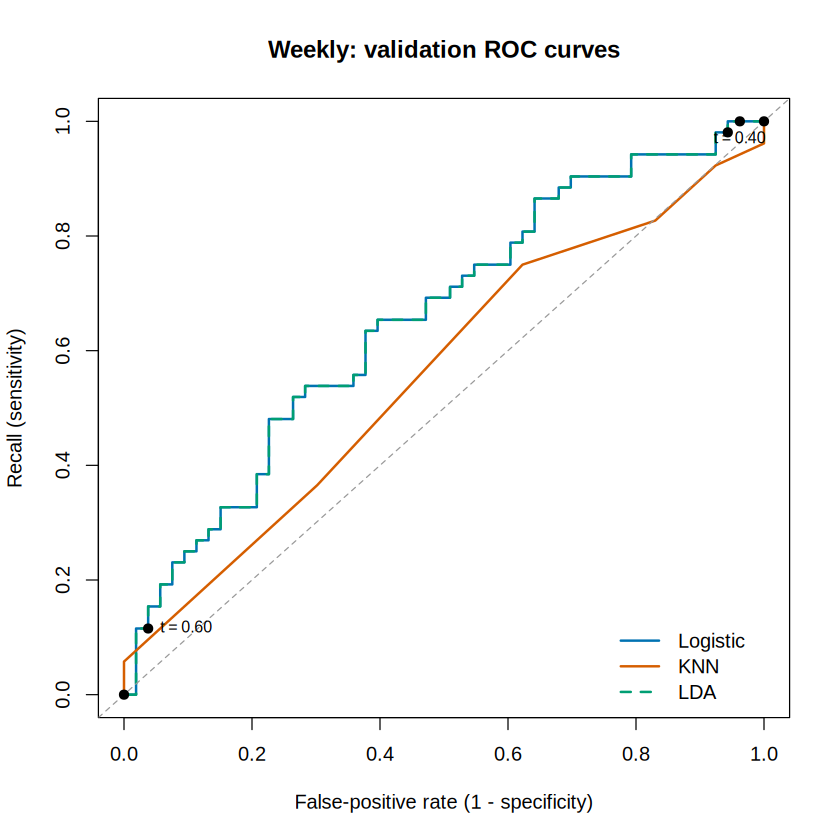

In [16]:
roc_colors <- c("#0072B2", "#D55E00", "#009E73")
roc_lty <- c(1, 1, 2)  # dashed LDA remains visible if ROC curves overlap
plot(1 - w_rocs[[1]]$specificities, w_rocs[[1]]$sensitivities,
     type = "l", col = roc_colors[1], lwd = 2,
     xlim = c(0, 1), ylim = c(0, 1),
     xlab = "False-positive rate (1 - specificity)",
     ylab = "Recall (sensitivity)", main = "Weekly: validation ROC curves")
for (j in 2:3) {
  lines(1 - w_rocs[[j]]$specificities, w_rocs[[j]]$sensitivities,
        col = roc_colors[j], lwd = 2, lty = roc_lty[j])
}
abline(0, 1, lty = 2, col = "gray60")
points(w_thresholds$FPR, w_thresholds$recall, pch = 19)
# Label two well-separated operating points; all five appear in the table.
w_mark <- subset(w_thresholds, threshold %in% c(.40, .60))
text(w_mark$FPR, w_mark$recall,
     labels = paste0("t = ", format(w_mark$threshold, nsmall = 2)),
     pos = c(1, 4), cex = .8)
legend("bottomright", legend = names(w_rocs), col = roc_colors,
       lwd = 2, lty = roc_lty, bty = "n")

In [17]:
w_auc <- data.frame(method = names(w_rocs),
                    validation_AUC = vapply(w_rocs, function(r) {
                      as.numeric(pROC::auc(r))
                    }, numeric(1)))
w_auc

,method,validation_AUC
,<chr>,<dbl>
Logistic,Logistic,0.6545718
KNN,KNN,0.5600508
LDA,LDA,0.6545718


In [18]:
w_thresholds[round(w_thresholds$threshold, 2) %in% c(0.40, 0.60),
             c("threshold", "TP", "FN", "FP", "TN", "recall", "FPR")]


,threshold,TP,FN,FP,TN,recall,FPR
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
2,0.4,52,0,51,2,1.0000000,0.96226415
4,0.6,6,46,2,51,0.1153846,0.03773585


Question 3.1

In [19]:
# Verify recall from the counts for one threshold.
row50 <- w_thresholds[round(w_thresholds$threshold, 2) == 0.50, ]
row50$TP / (row50$TP + row50$FN)
row50$recall

row50[, c("threshold","TP","FN","FP","TN")]

w_thresholds[, c("threshold", "FN", "FP", "cost")]
w_selected_t
w_thresholds$cost[match(w_selected_t, w_thresholds$threshold)]

[1] 0.9807692

[1] 0.9807692

,threshold,TP,FN,FP,TN
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
3,0.5,51,1,50,3


threshold,FN,FP,cost
<dbl>,<dbl>,<dbl>,<dbl>
0.3,0,53,53
0.4,0,51,51
0.5,1,50,52
0.6,46,2,94
0.7,52,0,104


[1] 0.4

[1] 51

I compared the thresholds 0.40 and 0.60. At threshold 0.40: TP = 52, FN = 0, FP = 51, TN = 2, recall = 1.000, and FPR = 0.962. At threshold 0.60: TP = 6, FN = 46, FP = 2, TN = 51, recall = 0.115, and FPR = 0.038.

The two types of mistakes change because the threshold is based on how sure the model has to be before it says "up." A low threshold means it says “Up” even when it is only a little bit sure. A high threshold means it only says “Up” when it is very sure. So a higher threshold means fewer false positives but more false negatives, and recall and the false-positive rate both go down.

The cost is 2 x FN + FP. The costs for thresholds 0.30, 0.40, 0.50, 0.60, and 0.70 are 53, 51, 52, 94, and 104. The cost rule chooses threshold 0.40, which has the lowest validation cost of 51.

At threshold 0.50, FN = 1 and TP = 51, so recall = 51 / (51 + 1) = 51 / 52 = 0.981. This matches the recall that R reported (0.981).

Question 3.2

The validation AUC values are: logistic regression = 0.655, KNN = 0.560, and LDA = 0.655.

If I pick one Up week and one Down week at random, the AUC is the chance that the Up week gets a higher score from the model than the Down week. If both weeks get exactly the same score, that pair counts as half correct. For logistic regression, an AUC of 0.655 means the Up week gets the higher score in about 65 out of 100 random Up/Down pairs. An AUC of 0.5 is about the same as guessing and 1 would mean it always ranks the Up week higher.

AUC only looks at how the model ranks the weeks from most likely Up to least likely Up, and it uses every possible threshold. Accuracy at 0.50 uses just one cutoff and counts how many predictions are correct. A model can rank the weeks well but still have poor accuracy at 0.50 if 0.50 is not a good cutoff for it.

Question 3.3

In [20]:
roc_sq <- pROC::roc(w_valid$Direction, w_glm_valid^2,
                    levels = c("Down", "Up"), direction = "<", quiet = TRUE)
as.numeric(pROC::auc(roc_sq))
as.numeric(pROC::auc(w_rocs$Logistic))
best_k
w_selected_t

[1] 0.6545718

[1] 0.6545718

[1] 11

[1] 0.4

The AUC with the original logistic probabilities and with the squared probabilities are both 0.655, so AUC does not change.

It doesn't change because AUC only cares about the order of the scores, meaning which week is ranked higher than another. Probabilities are between 0 and 1, and squaring a number between 0 and 1 keeps the order.Since no weeks switch places, the AUC stays exactly the same.

AUC does not tell us if the probabilities are right, it only tells us how well the model ranks the weeks. The model can have a good AUC but still give probabilities that don't match what really happens.

best_k = 11 and w_selected_t = 0.40

Section 4 - Default: explore imbalance and build a baseline

In [21]:
default <- ISLR2::Default
default$default <- factor(default$default, levels = c("No", "Yes"))
default$student <- factor(default$student, levels = c("No", "Yes"))

RNGkind("Mersenne-Twister", "Inversion", "Rejection")
set.seed(4630)
d_split <- rep(NA_character_, nrow(default))
for (lev in levels(default$default)) {
  ids <- sample(which(default$default == lev))
  n_train <- floor(.60 * length(ids))
  n_valid <- floor(.20 * length(ids))
  d_split[ids[seq_len(n_train)]] <- "train"
  d_split[ids[n_train + seq_len(n_valid)]] <- "validation"
  d_split[ids[(n_train + n_valid + 1):length(ids)]] <- "test"
}
d_train <- default[d_split == "train", ]
d_valid <- default[d_split == "validation", ]
d_test  <- default[d_split == "test", ]
table(d_split)

d_split
      test      train validation 
      2002       5999       1999 

In [22]:
str(d_train)
colSums(is.na(d_train))
summary(d_train)
table(d_train$default)
prop.table(table(d_train$default))
prop.table(table(student = d_train$student, default = d_train$default), 1)

'data.frame':	5999 obs. of  4 variables:
 $ default: Factor w/ 2 levels "No","Yes": 1 1 1 1 1 1 1 1 1 1 ...
 $ student: Factor w/ 2 levels "No","Yes": 1 2 1 2 1 1 2 1 1 2 ...
 $ balance: num  786 920 826 809 1161 ...
 $ income : num  38463 7492 24905 17600 37469 ...


default student balance  income 
      0       0       0       0

 default    student       balance           income     
 No :5800   No :4213   Min.   :   0.0   Min.   :  772  
 Yes: 199   Yes:1786   1st Qu.: 490.0   1st Qu.:21146  
                       Median : 831.6   Median :34556  
                       Mean   : 841.1   Mean   :33538  
                       3rd Qu.:1165.8   3rd Qu.:44119  
                       Max.   :2654.3   Max.   :73554  


  No  Yes 
5800  199 


       No       Yes 
0.9668278 0.0331722 

       default
student         No        Yes
    No  0.97080465 0.02919535
    Yes 0.95744681 0.04255319

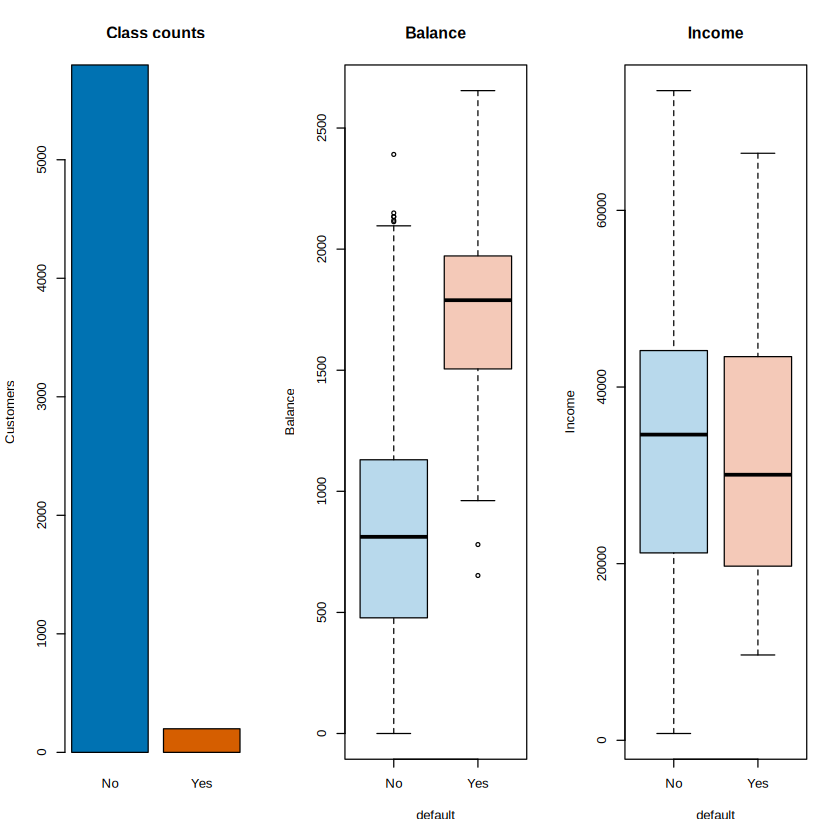

In [23]:
old_par <- par(mfrow = c(1, 3))
barplot(table(d_train$default), col = c("#0072B2", "#D55E00"),
        main = "Class counts", ylab = "Customers")
boxplot(balance ~ default, data = d_train,
        col = c("#B8D9EC", "#F4C9B8"), ylab = "Balance", main = "Balance")
boxplot(income ~ default, data = d_train,
        col = c("#B8D9EC", "#F4C9B8"), ylab = "Income", main = "Income")
par(old_par)

In [24]:
d_majority <- names(which.max(table(d_train$default)))
stopifnot(d_majority == "No")

d_glm <- glm(default ~ balance + income + student,
             data = d_train, family = binomial())
summary(d_glm)
d_prob_valid <- as.numeric(predict(d_glm, newdata = d_valid, type = "response"))
d_valid_scores <- list("Always No" = rep(0, nrow(d_valid)),
                       "Logistic, t=0.50" = d_prob_valid)
d_valid_rocs <- lapply(d_valid_scores, function(p) {
  pROC::roc(d_valid$default, p, levels = c("No", "Yes"),
            direction = "<", quiet = TRUE)
})
d_validation <- do.call(rbind, lapply(names(d_valid_scores), function(method) {
  row <- pROC::coords(d_valid_rocs[[method]], x = .50,
                       input = "threshold", ret = metric_names) |>
    setNames(reported_names)
  predicted <- factor(ifelse(d_valid_scores[[method]] >= .50, "Yes", "No"),
                       levels = levels(d_valid$default))
  row$F1 <- yardstick::f_meas_vec(d_valid$default, predicted,
                                 event_level = "second")
  row$balanced_accuracy <- yardstick::bal_accuracy_vec(
    d_valid$default, predicted, event_level = "second")
  cbind(method = method, row)
}))
rownames(d_validation) <- NULL
d_baseline_valid <- d_validation[1, -1]
d_at_half <- d_validation[2, -1]
d_validation


Call:
glm(formula = default ~ balance + income + student, family = binomial(), 
    data = d_train)

Coefficients:
              Estimate Std. Error z value Pr(>|z|)    
(Intercept) -1.077e+01  6.277e-01 -17.158   <2e-16 ***
balance      5.641e-03  2.942e-04  19.173   <2e-16 ***
income       3.475e-06  1.025e-05   0.339   0.7346    
studentYes  -5.579e-01  2.971e-01  -1.878   0.0604 .  
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

(Dispersion parameter for binomial family taken to be 1)

    Null deviance: 1746.93  on 5998  degrees of freedom
Residual deviance:  958.34  on 5995  degrees of freedom
AIC: 966.34

Number of Fisher Scoring iterations: 8


Warning message:
“While computing binary `precision()`, no predicted events were detected (i.e.
`true_positive + false_positive = 0`).
Precision is undefined in this case, and `NA` will be returned.
Note that 66 true event(s) actually occurred for the problematic event level, Yes”


method,threshold,TP,FN,FP,TN,accuracy,recall,specificity,FPR,precision,F1,balanced_accuracy
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Always No,0.5,0,66,0,1933,0.9669835,0.0000000,1.000000,0.000000000,NaN,NA,0.5000000
"Logistic, t=0.50",0.5,18,48,9,1924,0.9714857,0.2727273,0.995344,0.004655975,0.6666667,0.3870968,0.6340356


Question 4.1

Out of 5,999 training customers, 199 defaulted. That is 3.317% of the training customers.

There are no missing values.

Balance: Customers who defaulted tend to have much higher balances. The median for defaulters is around 1,800, compared with around 800 for customers who did not default, and the two boxes barely overlap.

Income: The two groups look very similar. The boxes overlap a lot, and the median income is only slightly lower for customers who defaulted (about 30,000 to about 34,500).

Balance shows the clearer difference between customers who default and those who do not, since its boxes are separated while the income boxes mostly overlap.

Question 4.2

In [25]:
d_validation

method,threshold,TP,FN,FP,TN,accuracy,recall,specificity,FPR,precision,F1,balanced_accuracy
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Always No,0.5,0,66,0,1933,0.9669835,0.0000000,1.000000,0.000000000,NaN,NA,0.5000000
"Logistic, t=0.50",0.5,18,48,9,1924,0.9714857,0.2727273,0.995344,0.004655975,0.6666667,0.3870968,0.6340356


Accuracy: 0.967
Recall: 0
Specificity = 1.000
Precision = NaN
F1 = NA
Balanced accuracy = 0.5000000

Only 66 of the 1,999 validation customers actually default, so predicting “No” for everyone is right only about 96.7% of the time which is why the accuracy looks high. But the rule never finds a single default (recall = 0). It looks very accurate, but it never catches the customers we care about most. Balanced accuracy of 0.500 shows it is no better than guessing.

Precision measures how many of the customers the model predicted as “Yes” really defaulted. The always-No rule never predicts “Yes,” so there are no predicted defaults to check, and precision works out to 0 divided by 0, which is undefined (NaN). F1 is calculated using precision, so it is also undefined (NA).

Question 4.3

In [26]:
d_validation[, c("method", "accuracy", "FN", "recall")]
exp(100 * coef(d_glm)["balance"])

method,accuracy,FN,recall
<chr>,<dbl>,<dbl>,<dbl>
Always No,0.9669835,66,0.0000000
"Logistic, t=0.50",0.9714857,48,0.2727273


balance 
1.757876

The two accuracies are almost the same (0.967 vs. 0.971). But the always-No rule misses all 66 defaulters (FN = 66, recall = 0) while logistic regression misses 48 and catches 18 (recall = 0.273). So logistic regression is better at finding defaulters, even though its accuracy is only slightly higher.

exp(100 x coef for balance) = 1.758. This means that when balance goes up by 100 units, and income and student status stay the same, the odds of default are multiplied by about 1.758.

This is not the same as a change in probability because the odds ratio tells us how much the odds are multiplied, not how much the probability goes up. How much the probability changes depends on the customer's starting probability, so the same odds ratio gives a different change in probability for different customers.



Section 5-Default: compare metrics and choose a threshold

Question 5.1

In [27]:
d_cuts <- c(.01, .03, .05, .10, .20, .30, .50)
d_thresholds <- pROC::coords(d_valid_rocs[["Logistic, t=0.50"]],
                             x = d_cuts, input = "threshold", ret = metric_names) |>
  setNames(reported_names)
d_thresholds$F1 <- vapply(d_cuts, function(cut) {
  predicted <- factor(ifelse(d_prob_valid >= cut, "Yes", "No"),
                       levels = levels(d_valid$default))
  yardstick::f_meas_vec(d_valid$default, predicted, event_level = "second")
}, numeric(1))
d_thresholds$balanced_accuracy <- vapply(d_cuts, function(cut) {
  predicted <- factor(ifelse(d_prob_valid >= cut, "Yes", "No"),
                       levels = levels(d_valid$default))
  yardstick::bal_accuracy_vec(d_valid$default, predicted, event_level = "second")
}, numeric(1))
d_thresholds

# Apply the assigned policy using standard filtering and ordering functions.
d_eligible <- subset(d_thresholds, recall >= .70 & !is.na(precision))
if (nrow(d_eligible) > 0) {
  d_ranked <- d_eligible[order(-d_eligible$precision, -d_eligible$threshold), ]
} else {
  d_ranked <- d_thresholds[order(-d_thresholds$recall, -d_thresholds$precision,
                                -d_thresholds$threshold, na.last = TRUE), ]
}
d_selected_t <- d_ranked$threshold[1]
d_selected_row <- match(d_selected_t, d_thresholds$threshold)
d_target_met <- d_thresholds$recall[d_selected_row] >= .70
d_thresholds[d_selected_row, ]
d_target_met


d_thresholds[,c("threshold","TP","FN","FP","TN","accuracy","recall","specificity",
                "precision","F1")]

d_four_thresholds<-subset(d_thresholds,
                          threshold %in% c(.05,.10,.30,.50))
d_no_predictions<-subset(d_validation,method=="Always No")
d_four_thresholds$method<-c("Logistic 0.05","Logistic 0.10","Logistic 0.30","Logistic 0.50")

columns<- c("method","threshold","TP","FN","FP",
                "TN","F1","accuracy","recall","specificity","FPR","precision"
              ,"balanced_accuracy")
d_results<-rbind(d_no_predictions[,columns],d_four_thresholds[,columns])
d_results


threshold,TP,FN,FP,TN,accuracy,recall,specificity,FPR,precision,F1,balanced_accuracy
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
0.01,66,0,502,1431,0.7488744,1.0000000,0.7403001,0.259699948,0.1161972,0.2082019,0.8701500
0.03,62,4,278,1655,0.8589295,0.9393939,0.8561821,0.143817900,0.1823529,0.3054187,0.8977880
0.05,58,8,195,1738,0.8984492,0.8787879,0.8991205,0.100879462,0.2292490,0.3636364,0.8889542
0.10,51,15,111,1822,0.9369685,0.7727273,0.9425763,0.057423694,0.3148148,0.4473684,0.8576518
0.20,42,24,48,1885,0.9639820,0.6363636,0.9751681,0.024831868,0.4666667,0.5384615,0.8057659
0.30,36,30,26,1907,0.9719860,0.5454545,0.9865494,0.013450595,0.5806452,0.5625000,0.7660020
0.50,18,48,9,1924,0.9714857,0.2727273,0.9953440,0.004655975,0.6666667,0.3870968,0.6340356


,threshold,TP,FN,FP,TN,accuracy,recall,specificity,FPR,precision,F1,balanced_accuracy
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
4,0.1,51,15,111,1822,0.9369685,0.7727273,0.9425763,0.05742369,0.3148148,0.4473684,0.8576518


[1] TRUE

threshold,TP,FN,FP,TN,accuracy,recall,specificity,precision,F1
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
0.01,66,0,502,1431,0.7488744,1.0000000,0.7403001,0.1161972,0.2082019
0.03,62,4,278,1655,0.8589295,0.9393939,0.8561821,0.1823529,0.3054187
0.05,58,8,195,1738,0.8984492,0.8787879,0.8991205,0.2292490,0.3636364
0.10,51,15,111,1822,0.9369685,0.7727273,0.9425763,0.3148148,0.4473684
0.20,42,24,48,1885,0.9639820,0.6363636,0.9751681,0.4666667,0.5384615
0.30,36,30,26,1907,0.9719860,0.5454545,0.9865494,0.5806452,0.5625000
0.50,18,48,9,1924,0.9714857,0.2727273,0.9953440,0.6666667,0.3870968


,method,threshold,TP,FN,FP,TN,F1,accuracy,recall,specificity,FPR,precision,balanced_accuracy
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,Always No,0.50,0,66,0,1933,NA,0.9669835,0.0000000,1.0000000,0.000000000,NaN,0.5000000
3,Logistic 0.05,0.05,58,8,195,1738,0.3636364,0.8984492,0.8787879,0.8991205,0.100879462,0.2292490,0.8889542
4,Logistic 0.10,0.10,51,15,111,1822,0.4473684,0.9369685,0.7727273,0.9425763,0.057423694,0.3148148,0.8576518
6,Logistic 0.30,0.30,36,30,26,1907,0.5625000,0.9719860,0.5454545,0.9865494,0.013450595,0.5806452,0.7660020
7,Logistic 0.50,0.50,18,48,9,1924,0.3870968,0.9714857,0.2727273,0.9953440,0.004655975,0.6666667,0.6340356


Question 5.1: The Always No model has an undefined precision because it never predicts any customers as defaulting. There are no positive predictions to calculate precision. Its F1 score is also undefined. For the logistic regression model(threshold of 0.10) the precision is 0.315. This indicates that about 31.5% of customers  predicted to default actually defaulted. The recall is 0.773 which means that the model identified 77.3% of customers who actually defaulted.  

Question 5.2
a)The chosen threshold has a value of 0.10 . The recall has a value of 0.773 or 77.3%. The precision has a value of 0.315 or 31.5%. The recall meets the minimum requirement of 0.70.
b) For threshold 0.10 the model has 111 false positives and 15 false negatives. For threshold 0.50 the model has 9 false positives and 48 false negatives. Therefore using a threshold 0.10 gives 102 more false positives. However, 0.10 threshold gives 33 fewer false negatives.
c)The 0.30 threshold has the highest F1 score of 0.563 as shown below. The precision is 0.581 and the recall is 0.545.
d)The highest F1 threshold differs from the chosen threshold because F1 balances both precision and recall while the assigned selection rule requires recall of at least 0.70. The threshold of 0.30 has the greatest F1 score but its recall of 0.545 does not meet the minimum requirement.
e)The test should only be used for the final evaluation. If we use test results to choose a threshold it risks overfitting the decision to the test data and getting an optimistic estimate of model performacne.

5.2 c) The threshold with the highest F1

In [28]:
d_F1<-d_thresholds[order(-d_thresholds$F1,-d_thresholds$threshold),]
d_F1[1,c("threshold","F1","precision","recall")]

,threshold,F1,precision,recall
,<dbl>,<dbl>,<dbl>,<dbl>
6,0.3,0.5625,0.5806452,0.5454545


Question 5.3

5.3:
1) The main metric is recall. Another metric is precision. Recall is important because we want to identify as many customers who actually default as possible. At threshold 0.05 the recall is 0.879 or 87.9%. The precision is 0.229 or 22.9%. This threshold catches a large proportion of actual defaults but many flagged customers won't default.

2) The main metric is precision and another metric is recall. Precision is important because the team wants a high proportion of flagged customers to actually be defaulters. At threshold 0.50 the precision is 0.667 or 66.7%. The recall is 0.273 or 27.3%. This indicates that fewer false alarms among flagged customers but the model misses many actual defaults.

Accuracy and specificity are not enough because most customers do not default and a model can score highly by always predicting no. One example is the Always no model has an accuracy of 0.967 and specificity of 1.00 but a recall of 0. F1 combines precision and recall into one score and balanced accuracy considers both recall and specificity. They both provide a more balanced evaluation than accuracy alone. However neither fully accounts for costs of different errors. The best metric depends on whether missing actual defaults or incorrectly flagging customers is more costly.

Section 6 - Group checkpoint

Case A: The issue is that Maya uses Today to predict the current weeks direction. But Today already has the return for that week so it is giving the model data about the outcome that it is supposed to predict.

Why it matters: This matters because it leads to data leakage because the model has information that wouldn't have been available before the prediction. This causes data leakage and makes the models performance appear better than it actually is.

How to fix it: This can be fixed by using predictors that are available before the week starts. For example only using variables such as Lag1 and Lag2.

Case B:
What is wrong: The issue is that Leo is scaling the validaiton data separately from the training data and uses different means and standard deviation.

Why it matters: This matters because KNN uses distances to make predictions. This means that using different scales can cause distance comparisons between the training observations and validation observations be unreliable. This can cause innacurate predictions.


How to fix it: This can be fixed by calculating the mean and the standard deviation from the training data. Then use the values and scale the validation data.

Case C:
Whats wrong: The issue is that Ana believes that 97% accuracy indicates the Always no rule does well. Ana also claims that precision is 100% which is inaccurate

Why it matters: This matters because the model always predicts no , therefore it misses every actual default. It gives it a recall of 0. The precision is not defined because the model never predicts a positive class.

How to fix it: This can be fixed by using the confusion matrix and evaluating other metrics. Recall and precision can be evaluated rather than relying on accuracy only.

Case D:
Whats wrong: The issue is that Ben chooses the threshold with the highest F1 score using the test data. Then Ben evaluates the model on that same data.

Why it matters: This matters because using the test dataset for model selection can cause data leakage and test set contamination. It causes an inaccurate estimate of the models performance and prediction because the test data influenced the threshold selection.

How to fix it: This can be fixed by selecting the threshold using validation data rather than test data. Then evaluate the final model once at the final step on the untouched test data.

AI Use statement: I used AI for assistance for working through explanations and checking if I was understanding the content correctly. I verified its contribution by making sure I understood everything and making sure to verify with the course notes. I used AI for reworking snippets of code as well, as there were times where my code may have been bulky or inefficient. I verified its contribution by running through the output produced by AI, making sure it was feasible/sensible, and making sure it aligned with the content in the lecture slides.